## **An example of remote access to Image Data Cube**

## **Background**
This exercise will give introduction to an example of remote sensing big data. There are many providers of remote sensing big data service, both public and proprietary. Examples include Copernicus Data Space, Google Earth Engine, Microsoft Planetary Computer (MPC), Digital Earth Africa, etc.  We will explore the MPC remote sensing big data service here, with Sentinel-2 imagery as the main dataset.

Microsoft Planetary Computer (MPC) is a cloud platform that hosts petabytes of Earth observation and environmental datasets, including Sentinel-2, Landsat, DEMs, climate data, and more. It provides a STAC (SpatioTemporal Asset Catalog) API for searching data and cloud-optimized storage for analysis. In MPC, evry satellite scene has metadata describing: 
    - Where it was acquired
    - When it was acquired
    - Which satellite acquired it
    - Its cloud cover
    - Which files (bands) belong to the scene
    - The coordinate system and spatial extent.

Sentinel-2 is an Earth observation mission from the EU Copernicus Programme that systematically acquires optical imagery at high spatial resolution (up to 10 m for some bands). The mission is based on a constellation of two identical satellites in the same orbit, 180° apart for optimal coverage and data delivery. Together, they cover all Earth's land surfaces, large islands, inland and coastal waters every 3-5 days.

MPC organises S2 imagery as **collections**, image archives. Each satellite acquisition is stored as an **item** with its metadata. The actual image bands are stored as **assets**. Then the stackstac package builds **virtual data cube** of desired content and size.  The data cube is read lazily, with Dask backend. It is up to the user to fetch the actual data y computing. 


## **Getting started**

To run this analysis, run all the cells in the notebook, starting with the "Load packages" cell. Start by installing the necessary packages if you do not have yet.

**Install the necessary packages**

In [1]:
#!pip install zarr 
#!pip install 'fsspec>=0.3.3'
#!pip install fsspec[http]
#!pip install pystac-client
#!pip install planetary-computer
#!pip install stackstac

**Initialize Dask for parallel computation**

In [2]:

from dask.distributed import Client
client = Client()
client


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 5
Total threads: 10,Total memory: 16.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:54984,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:55000,Total threads: 2
Dashboard: http://127.0.0.1:55002/status,Memory: 3.20 GiB
Nanny: tcp://127.0.0.1:54987,


2026-10-13 11:29:20,123 - tornado.application - ERROR - Uncaught exception GET /workers/ws (127.0.0.1)
HTTPServerRequest(protocol='http', host='127.0.0.1:8787', method='GET', uri='/workers/ws', version='HTTP/1.1', remote_ip='127.0.0.1')
Traceback (most recent call last):
  File "/Users/simenkrogstie/Documents/Programming/H26/GMFM350/.venv/lib/python3.12/site-packages/tornado/websocket.py", line 965, in _accept_connection
    open_result = handler.open(*handler.open_args, **handler.open_kwargs)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/simenkrogstie/Documents/Programming/H26/GMFM350/.venv/lib/python3.12/site-packages/tornado/web.py", line 3546, in wrapper
    return method(self, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/simenkrogstie/Documents/Programming/H26/GMFM350/.venv/lib/python3.12/site-packages/bokeh/server/views/ws.py", line 167, in open
    raise ProtocolError("Token is expired. Configure the app with

In [3]:
%matplotlib inline
import os
import pystac_client
import planetary_computer
import stackstac
from osgeo import gdal
import rasterio
import rioxarray
import matplotlib.pyplot as plt
import numpy as np

In [4]:
import requests; print('requests OK')

requests OK


In [5]:
import importlib.util
print(importlib.util.find_spec("planetary_computer"))

ModuleSpec(name='planetary_computer', loader=<_frozen_importlib_external.SourceFileLoader object at 0x114bc07a0>, origin='/Users/simenkrogstie/Documents/Programming/H26/GMFM350/.venv/lib/python3.12/site-packages/planetary_computer/__init__.py', submodule_search_locations=['/Users/simenkrogstie/Documents/Programming/H26/GMFM350/.venv/lib/python3.12/site-packages/planetary_computer'])


**Connect as a client to the MPC and create a catalogue**

In [6]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

**Search the catalogue with defined area, date and other criteria**

In [7]:
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[10.5, 59.5, 11.5, 60.0],
    datetime="2024-05-01/2024-09-30",
    query={
        "eo:cloud_cover": {"lt": 20},
        "s2:mgrs_tile": {"eq": "32VPM"}
        }
)

**Explore the search results**

In [8]:
items = list(search.items())
print(len(items))

20


In [9]:
for i, item in enumerate(items):
    print(i, item.id)
    """
    for asset in ["B04"]:
        proj = item.assets[asset].extra_fields["proj:epsg"]
        print("EPSG =", proj)
    """

0 S2A_MSIL2A_20240920T102721_R108_T32VPM_20240920T145352
1 S2A_MSIL2A_20240906T104621_R051_T32VPM_20240906T152550
2 S2B_MSIL2A_20240905T102559_R108_T32VPM_20240905T163108
3 S2B_MSIL2A_20240901T104619_R051_T32VPM_20240901T134205
4 S2A_MSIL2A_20240831T103021_R108_T32VPM_20240831T151747
5 S2B_MSIL2A_20240819T103629_R008_T32VPM_20240819T133835
6 S2B_MSIL2A_20240816T102559_R108_T32VPM_20240816T134838
7 S2B_MSIL2A_20240812T104629_R051_T32VPM_20240812T134520
8 S2A_MSIL2A_20240811T103031_R108_T32VPM_20240811T164252
9 S2B_MSIL2A_20240802T104619_R051_T32VPM_20240802T133951
10 S2A_MSIL2A_20240625T103631_R008_T32VPM_20240625T180524
11 S2B_MSIL2A_20240620T103629_R008_T32VPM_20240620T141331
12 S2A_MSIL2A_20240523T103021_R108_T32VPM_20240523T191409
13 S2B_MSIL2A_20240521T103619_R008_T32VPM_20240521T135010
14 S2A_MSIL2A_20240519T105031_R051_T32VPM_20240519T171703
15 S2B_MSIL2A_20240518T102559_R108_T32VPM_20240518T143106
16 S2A_MSIL2A_20240516T104021_R008_T32VPM_20240516T191809
17 S2A_MSIL2A_20240513T1

**Create a virtual datacube from the search results**

Each variable is a three-dimensional array with coordinates: time, bands, northing (y), and eating (x) in coordinates (EPSG). Even individual variable or band would require a lot of RAM to be kept in memory. The  data structure enables us to seamlessly fetch small portions of each variable. Furthermore, the system is based on ‘delayed execution’, an overview such as shown below is merely a description of the data, no actual data was fetched (yet).

In [10]:
signed_items = [planetary_computer.sign(item) for item in items]
cube = stackstac.stack(
    signed_items,
    assets=["B02", "B03", "B04", "B08"],
    epsg=32632, # UTM 33N
    #chunksize=1098,
    resolution=10
)
print(cube)

<xarray.DataArray 'stackstac-7198fe681f7d4c9a488325f89ec80e62' (time: 20,
                                                                band: 4,
                                                                y: 11899,
                                                                x: 11903)> Size: 91GB
dask.array<fetch_raster_window, shape=(20, 4, 11899, 11903), dtype=float64, chunksize=(1, 1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates: (12/46)
  * time                                     (time) datetime64[ns] 160B 2024-...
    id                                       (time) <U54 4kB 'S2B_MSIL2A_2024...
    s2:vegetation_percentage                 (time) float64 160B 56.92 ... 72.04
    s2:reflectance_conversion_factor         (time) float64 160B 0.9855 ... 0...
    s2:product_uri                           (time) <U65 5kB 'S2B_MSIL2A_2024...
    s2:granule_id                            (time) <U62 5kB 'S2B_OPER_MSI_L2...
    ...                                       ...
    c

**Take a look at the time range covered.**

In [11]:
cube.time.min().data, cube.time.max().data

(array('2024-05-04T10:46:19.024000000', dtype='datetime64[ns]'),
 array('2024-09-20T10:27:21.025000000', dtype='datetime64[ns]'))

**Select data from a specific date (time) or closest to it.**

In [12]:
cube_july=cube.sel(time='2024-07-01', method='nearest')
cube_july

<xarray.DataArray 'stackstac-7198fe681f7d4c9a488325f89ec80e62' (band: 4,
                                                                y: 11899,
                                                                x: 11903)> Size: 5GB
dask.array<getitem, shape=(4, 11899, 11903), dtype=float64, chunksize=(1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates: (12/46)
  * band                                     (band) <U3 48B 'B02' ... 'B08'
    title                                    (band) <U20 320B 'Band 2 - Blue ...
    common_name                              (band) <U5 80B 'blue' ... 'nir'
    center_wavelength                        (band) float64 32B 0.49 ... 0.842
    full_width_half_max                      (band) float64 32B 0.098 ... 0.145
  * y                                        (y) float64 95kB 6.705e+06 ... 6...
    ...                                       ...
    platform                                 <U11 44B 'Sentinel-2A'
    proj:shape                               object 8B {10980}
    proj:bbox                                object 8B {600000.0, 6700020.0, ...
    gsd                                      int64 8B 10
    proj:transform                           object 8B {0.0, 600000.0, 10.0, ...
    epsg                                     int64 8B 32632
Attributes:
    spec:        RasterSpec(epsg=32632, bounds=(597070, 6585710, 716100, 6704...
    crs:         epsg:32632
    transform:   | 10.00, 0.00, 597070.00|\n| 0.00,-10.00, 6704700.00|\n| 0.0...
    resolution:  10

**Visualize the RGB of the first day of the data cube of the defined location.**

(500, 500, 3)


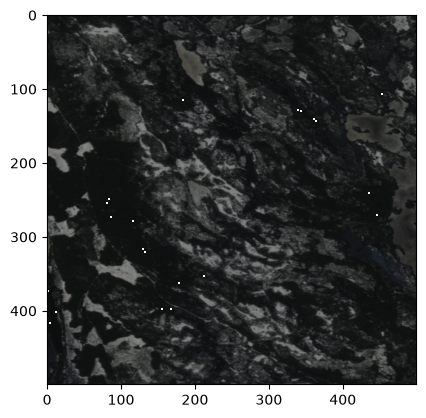

In [13]:
im=cube.isel(time=0)[:3,500:1000,500:1000]#[[ 'B02', 'B03', 'B04']]
im=im.transpose().values/18112.0
print(im.shape)
plt.imshow(im)

In [14]:
print(item.assets["B04"].extra_fields.keys())

dict_keys(['proj:bbox', 'proj:shape', 'proj:transform', 'gsd', 'eo:bands'])


In [15]:
item.assets["B04"]

<Asset href=https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/V/PM/2024/05/04/S2B_MSIL2A_20240504T104619_N0510_R051_T32VPM_20240504T132702.SAFE/GRANULE/L2A_T32VPM_A037400_20240504T104620/IMG_DATA/R10m/T32VPM_20240504T104619_B04_10m.tif?st=2026-10-12T09%3A29%3A21Z&se=2026-10-13T10%3A14%3A21Z&sp=rl&sv=2025-07-05&sr=c&skoid=9c8ff44a-6a2c-4dfb-b298-1c9212f64d9a&sktid=72f988bf-86f1-41af-91ab-2d7cd011db47&skt=2026-10-13T09%3A13%3A55Z&ske=2026-10-20T09%3A13%3A55Z&sks=b&skv=2025-07-05&sig=mubXJa4MTFnPhI6v7j7uxaiWzDR3Kd1m3FKL5pZNrz4%3D>

In [16]:
import json
d = item.to_dict()
print(json.dumps(d, indent=2)[:5000])

{
  "type": "Feature",
  "stac_version": "1.1.0",
  "stac_extensions": [
    "https://stac-extensions.github.io/eo/v1.1.0/schema.json",
    "https://stac-extensions.github.io/sat/v1.0.0/schema.json",
    "https://stac-extensions.github.io/projection/v2.0.0/schema.json"
  ],
  "id": "S2B_MSIL2A_20240504T104619_R051_T32VPM_20240504T132702",
  "geometry": {
    "type": "Polygon",
    "coordinates": [
      [
        [
          12.1307649,
          60.3963071
        ],
        [
          12.1165779,
          60.3788049
        ],
        [
          12.0036928,
          60.2383431
        ],
        [
          11.8908416,
          60.0979961
        ],
        [
          11.7800324,
          59.9573561
        ],
        [
          11.6695958,
          59.8167923
        ],
        [
          11.5601052,
          59.6761925
        ],
        [
          11.4518595,
          59.5354732
        ],
        [
          11.3683053,
          59.425967
        ],
        [
      

In [17]:
print(json.dumps(d.get("properties", {}), indent=2))

{
  "datetime": "2024-05-04T10:46:19.024000Z",
  "platform": "Sentinel-2B",
  "instruments": [
    "msi"
  ],
  "s2:mgrs_tile": "32VPM",
  "constellation": "Sentinel 2",
  "s2:granule_id": "S2B_OPER_MSI_L2A_TL_MSFT_20240504T132702_A037400_T32VPM_N05.10",
  "eo:cloud_cover": 12.376868,
  "s2:datatake_id": "GS2B_20240504T104619_037400_N05.10",
  "s2:product_uri": "S2B_MSIL2A_20240504T104619_N0510_R051_T32VPM_20240504T132702.SAFE",
  "s2:datastrip_id": "S2B_OPER_MSI_L2A_DS_MSFT_20240504T132702_S20240504T104620_N05.10",
  "s2:product_type": "S2MSI2A",
  "sat:orbit_state": "ascending",
  "s2:datatake_type": "INS-NOBS",
  "s2:generation_time": "2024-05-04T13:27:02.41954Z",
  "sat:relative_orbit": 51,
  "s2:water_percentage": 4.253503,
  "s2:mean_solar_zenith": 43.8266318929358,
  "s2:mean_solar_azimuth": 174.648442676106,
  "s2:processing_baseline": "05.10",
  "s2:snow_ice_percentage": 2.168559,
  "s2:vegetation_percentage": 56.91815,
  "s2:thin_cirrus_percentage": 12.35387,
  "s2:cloud_shad

In [18]:
for k, v in item.properties.items():
    if "epsg" in k.lower() or "proj" in k.lower():
        print(k, v)

proj:code EPSG:32632


In [19]:
cube.dims

('time', 'band', 'y', 'x')

In [20]:
print("x min/max:", cube.x.min().values, cube.x.max().values)
print("y min/max:", cube.y.min().values, cube.y.max().values)

x min/max: 597070.0 716090.0
y min/max: 6585720.0 6704700.0


In [21]:
subset = cube.sel(
    x=slice(600000, 605000),
    y=slice(6650000, 6651000)
)

In [22]:
red = cube.sel(band="B04")
nir = cube.sel(band="B08")

**Compute NDVI for the defined location, for the entire time range.**

In [23]:
NDVI = (nir - red) / (nir + red)

In [24]:
ndvi_ts = NDVI.mean(dim=["x", "y"]).compute()

In [25]:
print(ndvi_ts)

<xarray.DataArray 'stackstac-7198fe681f7d4c9a488325f89ec80e62' (time: 20)> Size: 160B
array([0.28046498, 0.30842411, 0.32072764, 0.32920855, 0.35875825,
       0.31387001, 0.35522725, 0.34696847, 0.42471968, 0.4309909 ,
       0.41778759, 0.41457527, 0.41175886, 0.4050186 , 0.39820856,
       0.37577381, 0.36410115, 0.36519652, 0.33270205, 0.31347695])
Coordinates: (12/39)
  * time                                     (time) datetime64[ns] 160B 2024-...
    id                                       (time) <U54 4kB 'S2B_MSIL2A_2024...
    s2:vegetation_percentage                 (time) float64 160B 56.92 ... 72.04
    s2:reflectance_conversion_factor         (time) float64 160B 0.9855 ... 0...
    s2:product_uri                           (time) <U65 5kB 'S2B_MSIL2A_2024...
    s2:granule_id                            (time) <U62 5kB 'S2B_OPER_MSI_L2...
    ...                                       ...
    constellation                            <U10 40B 'Sentinel 2'
    proj:shape       

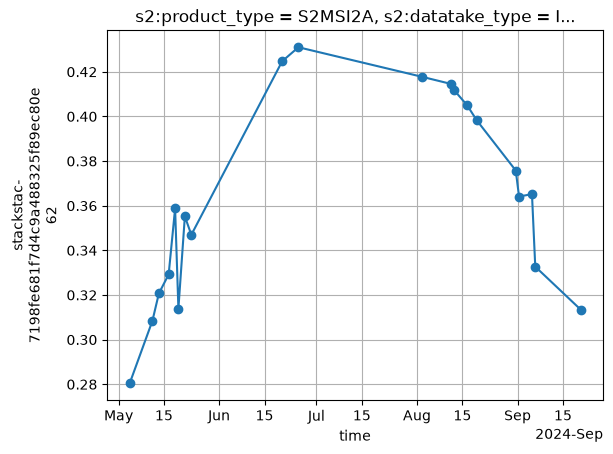

In [26]:
ndvi_ts.plot(marker="o")
plt.grid(True)
plt.show()

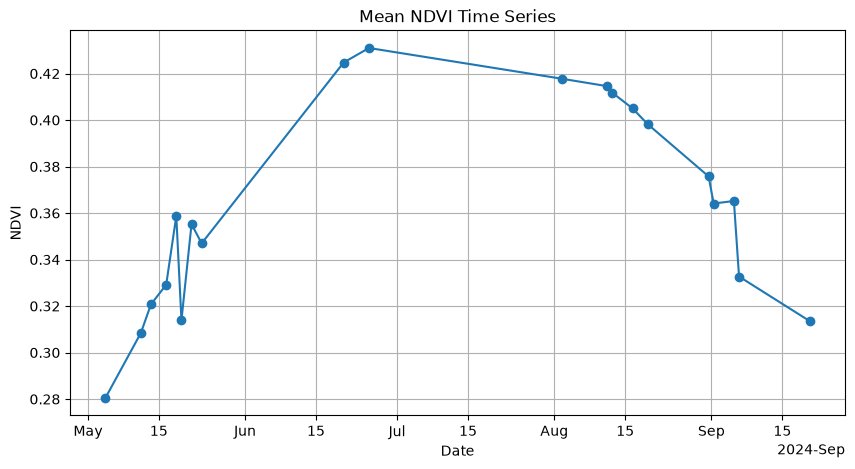

In [27]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5))
ndvi_ts.plot(ax=ax, marker="o")
plt.xlabel("Date")
plt.ylabel("NDVI")
plt.title("Mean NDVI Time Series")
plt.grid(True)

plt.show()

**Visulaize NDVI of the first date.**

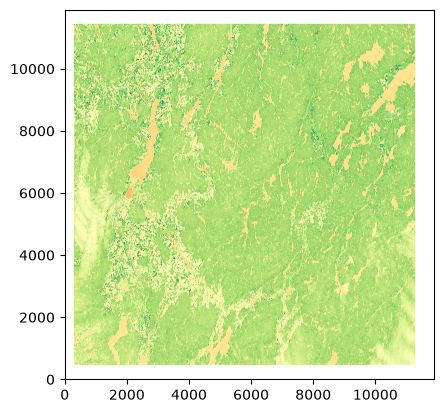

In [28]:
# Mean of all images/dates
plt.imshow(NDVI.isel(time=1), origin='lower', cmap='RdYlGn')

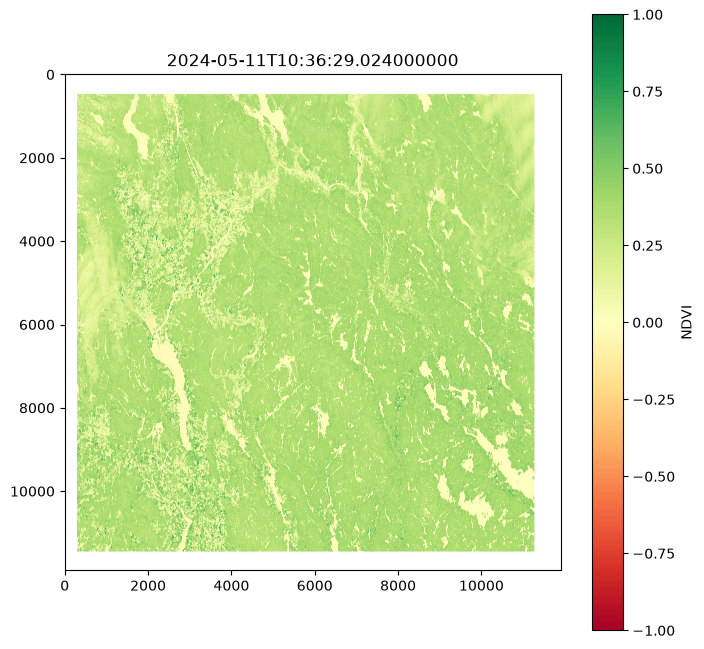

In [29]:
ndvi_first = NDVI.isel(time=1).compute()

plt.figure(figsize=(8,8))
plt.imshow(
    ndvi_first,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)
plt.colorbar(label="NDVI")
plt.title(str(ndvi_first.time.values))
plt.show()

In [30]:
# Close the Dask client
client.close()